In [18]:
from pathlib import Path
from itertools import islice

import pandas as pd
from Bio import SeqIO

# Find the project folder
current = Path.cwd()
PROJECT_ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "data" / "raw" / "cafa5").exists()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the CAFA 5 data folder.")

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "cafa5"

print("Project folder:", PROJECT_ROOT)
print("Dataset folder:", DATA_DIR)
print("Dataset folder exists:", DATA_DIR.exists())

Project folder: c:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction
Dataset folder: c:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\data\raw\cafa5
Dataset folder exists: True


In [19]:
from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

print("\nDATA_DIR is:")
print(DATA_DIR)

print("\nDoes DATA_DIR exist?")
print(DATA_DIR.exists())

print("\nFiles inside DATA_DIR:")
if DATA_DIR.exists():
    for file in DATA_DIR.iterdir():
        print(file.name)

Notebook working directory:
c:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\notebooks

DATA_DIR is:
c:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\data\raw\cafa5

Does DATA_DIR exist?
True

Files inside DATA_DIR:
IA.txt
sample_submission.tsv
Test (Targets)
Train


In [20]:
from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

print("\nDATA_DIR is:")
print(DATA_DIR)

print("\nDoes DATA_DIR exist?")
print(DATA_DIR.exists())

print("\nFiles inside DATA_DIR:")
if DATA_DIR.exists():
    for file in DATA_DIR.iterdir():
        print(file.name)

Notebook working directory:
c:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\notebooks

DATA_DIR is:
c:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\data\raw\cafa5

Does DATA_DIR exist?
True

Files inside DATA_DIR:
IA.txt
sample_submission.tsv
Test (Targets)
Train


In [21]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("Dataset folder:", DATA_DIR)
print("Folder exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    print("\nFiles found:")
    for file in DATA_DIR.iterdir():
        print(file.name)

Current folder: c:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\notebooks
Dataset folder: c:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\data\raw\cafa5
Folder exists: True

Files found:
IA.txt
sample_submission.tsv
Test (Targets)
Train


In [22]:
from pathlib import Path

# Check common locations on your computer
locations = [
    Path.home() / "Downloads" / "cafa-5-protein-function-prediction",
    Path.home() / "OneDrive" / "Desktop" / "protein-function-prediction" / "protein-function-prediction" / "data" / "raw" / "cafa5",
    Path.home() / "Desktop" / "protein-function-prediction" / "protein-function-prediction" / "data" / "raw" / "cafa5",
]

for folder in locations:
    print("\nChecking:", folder)
    print("Exists:", folder.exists())

    if folder.exists():
        print("Files:", [file.name for file in folder.iterdir()][:15])


Checking: C:\Users\pyaea\Downloads\cafa-5-protein-function-prediction
Exists: True
Files: ['IA.txt', 'sample_submission.tsv', 'Test (Targets)', 'Train']

Checking: C:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\data\raw\cafa5
Exists: True
Files: ['IA.txt', 'sample_submission.tsv', 'Test (Targets)', 'Train']

Checking: C:\Users\pyaea\Desktop\protein-function-prediction\protein-function-prediction\data\raw\cafa5
Exists: False


In [1]:
from pathlib import Path

DATA_DIR = (
    Path.home()
    / "OneDrive"
    / "Desktop"
    / "protein-function-prediction"
    / "protein-function-prediction"
    / "data"
    / "raw"
    / "cafa5"
)

print("Files inside Train:")
for file in (DATA_DIR / "Train").rglob("*"):
    if file.is_file():
        
        print(file.name, "->", file)

Files inside Train:
go-basic.obo -> C:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\data\raw\cafa5\Train\go-basic.obo
train_sequences.fasta -> C:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\data\raw\cafa5\Train\train_sequences.fasta
train_taxonomy.tsv -> C:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\data\raw\cafa5\Train\train_taxonomy.tsv
train_terms.tsv -> C:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\data\raw\cafa5\Train\train_terms.tsv


In [2]:
from pathlib import Path
import pandas as pd

# Set the correct dataset paths
PROJECT_ROOT = (
    Path.home()
    / "OneDrive"
    / "Desktop"
    / "protein-function-prediction"
    / "protein-function-prediction"
)

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "cafa5" / "Train"

# Load the protein function annotations
terms_path = DATA_DIR / "train_terms.tsv"
terms = pd.read_csv(terms_path, sep="\t")

print("Project folder:", PROJECT_ROOT)
print("Annotation file found:", terms_path.exists())
print("Annotation table shape:", terms.shape)

print("\nColumn names:")
print(terms.columns.tolist())

print("\nFirst five rows:")
display(terms.head())

Project folder: C:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction
Annotation file found: True
Annotation table shape: (5363863, 3)

Column names:
['EntryID', 'term', 'aspect']

First five rows:


,EntryID,term,aspect
0,A0A009IHW8,GO:0008152,BPO
1,A0A009IHW8,GO:0034655,BPO
2,A0A009IHW8,GO:0072523,BPO
3,A0A009IHW8,GO:0044270,BPO
4,A0A009IHW8,GO:0006753,BPO


In [3]:
# 1. Count annotation rows
print("Total annotation rows:", len(terms))

# 2. Count unique proteins and GO terms
print("Unique proteins:", terms["EntryID"].nunique())
print("Unique GO terms:", terms["term"].nunique())

# 3. Count annotations by GO aspect
print("\nAnnotations by GO aspect:")
print(terms["aspect"].value_counts())

# 4. Count unique GO terms in each aspect
print("\nUnique GO terms by aspect:")
print(
    terms.groupby("aspect")["term"]
    .nunique()
    .sort_values(ascending=False)
)

Total annotation rows: 5363863
Unique proteins: 142246
Unique GO terms: 31466

Annotations by GO aspect:
aspect
BPO    3497732
CCO    1196017
MFO     670114
Name: count, dtype: int64

Unique GO terms by aspect:
aspect
BPO    21285
MFO     7224
CCO     2957
Name: term, dtype: int64


In [4]:
from Bio import SeqIO

# Locate the protein sequence file
fasta_path = DATA_DIR / "train_sequences.fasta"

print("Sequence file exists:", fasta_path.exists())

# Read the first five protein sequences
for record in SeqIO.parse(fasta_path, "fasta"):
    print("Protein ID:", record.id)
    print("Sequence length:", len(record.seq))
    print("Sequence preview:", str(record.seq)[:60])
    print("-" * 50)

    # Stop after five sequences
    if record.id == "":
        break

Sequence file exists: True
Protein ID: P20536
Sequence length: 218
Sequence preview: MNSVTVSHAPYTITYHDDWEPVMSQLVEFYNEVASWLLRDETSPIPDKFFIQLKQPLRNK
--------------------------------------------------
Protein ID: O73864
Sequence length: 354
Sequence preview: MTEYRNFLLLFITSLSVIYPCTGISWLGLTINGSSVGWNQTHHCKLLDGLVPDQQQLCKR
--------------------------------------------------
Protein ID: O95231
Sequence length: 258
Sequence preview: MRLSSSPPRGPQQLSSFGSVDWLSQSSCSGPTHTPRPADFSLGSLPGPGQTSGAREPPQA
--------------------------------------------------
Protein ID: A0A0B4J1F4
Sequence length: 415
Sequence preview: MGGEAGADGPRGRVKSLGLVFEDESKGCYSSGETVAGHVLLEAAEPVALRGLRLEAQGRA
--------------------------------------------------
Protein ID: P54366
Sequence length: 415
Sequence preview: MVETNSPPAGYTLKRSPSDLGEQQQPPRQISRSPGNTAAYHLTTAMLLNSQQCGYLGQRL
--------------------------------------------------
Protein ID: P33681
Sequence length: 288
Sequence preview: MGHTRRQGTSPSKCPYLNFFQLLVLAGLSHFCSGVIHVTKEVKEVATLSCGHNVSVEELA


In [5]:
from Bio import SeqIO
import pandas as pd

fasta_path = DATA_DIR / "train_sequences.fasta"

# Collect protein IDs and sequence lengths
sequence_data = []

for record in SeqIO.parse(fasta_path, "fasta"):
    sequence_data.append({
        "EntryID": record.id,
        "sequence_length": len(record.seq)
    })

# Convert to a table
sequences = pd.DataFrame(sequence_data)

# Summary statistics
print("Total protein sequences:", len(sequences))
print("Unique protein IDs:", sequences["EntryID"].nunique())

print("\nSequence length statistics:")
display(sequences["sequence_length"].describe().to_frame())

print("\nFirst five sequences:")
display(sequences.head())

Total protein sequences: 142246
Unique protein IDs: 142246

Sequence length statistics:


,sequence_length
count,142246.000000
mean,553.636679
std,641.728770
min,3.000000
25%,248.000000
50%,411.000000
75%,654.000000
max,35375.000000



First five sequences:


,EntryID,sequence_length
0,P20536,218
1,O73864,354
2,O95231,258
3,A0A0B4J1F4,415
4,P54366,415


In [6]:
# Compare protein IDs in the annotation table and FASTA file
annotated_ids = set(terms["EntryID"].unique())
sequence_ids = set(sequences["EntryID"].unique())

print("Proteins with sequences:", len(sequence_ids))
print("Proteins with annotations:", len(annotated_ids))
print("Proteins in both datasets:", len(sequence_ids & annotated_ids))
print("Annotated proteins without sequences:", len(annotated_ids - sequence_ids))
print("Sequences without annotations:", len(sequence_ids - annotated_ids))

Proteins with sequences: 142246
Proteins with annotations: 142246
Proteins in both datasets: 142246
Annotated proteins without sequences: 0
Sequences without annotations: 0


In [7]:
# Count how many proteins are associated with each GO term
go_counts = (
    terms.groupby(["term", "aspect"])["EntryID"]
    .nunique()
    .reset_index(name="protein_count")
    .sort_values("protein_count", ascending=False)
)

print("Total unique GO terms:", len(go_counts))

print("\nTop 15 most common GO terms:")
display(go_counts.head(15))

print("\nTop 15 rarest GO terms:")
display(go_counts.tail(15).sort_values("protein_count"))

print("\nGO term frequency summary:")
display(go_counts["protein_count"].describe().to_frame())

Total unique GO terms: 31466

Top 15 most common GO terms:


,term,aspect,protein_count
3040,GO:0005575,CCO,92912
4616,GO:0008150,BPO,92210
25447,GO:0110165,CCO,91286
1867,GO:0003674,MFO,78637
3076,GO:0005622,CCO,70785
5955,GO:0009987,BPO,61293
14891,GO:0043226,CCO,60883
14894,GO:0043229,CCO,58315
3001,GO:0005488,MFO,57380
14892,GO:0043227,CCO,55452



Top 15 rarest GO terms:


,term,aspect,protein_count
5220,GO:0009012,MFO,1
26693,GO:1900925,BPO,1
15321,GO:0043916,MFO,1
10701,GO:0031741,MFO,1
18214,GO:0050303,MFO,1
18212,GO:0050297,MFO,1
18209,GO:0050292,MFO,1
18205,GO:0050285,MFO,1
18203,GO:0050281,MFO,1
12291,GO:0034240,BPO,1



GO term frequency summary:


,protein_count
count,31466.000000
mean,170.465359
std,1725.482889
min,1.000000
25%,3.000000
50%,8.000000
75%,35.000000
max,92912.000000


In [8]:
# Count proteins associated with each GO term
go_counts = (
    terms.groupby(["term", "aspect"])["EntryID"]
    .nunique()
    .reset_index(name="protein_count")
)

# Choose terms associated with at least 100 proteins
MIN_PROTEINS = 100

selected_terms = go_counts[
    go_counts["protein_count"] >= MIN_PROTEINS
].copy()

print("Total GO terms:", len(go_counts))
print("Selected GO terms:", len(selected_terms))
print("Minimum proteins per selected term:", MIN_PROTEINS)

print("\nSelected terms by aspect:")
print(selected_terms["aspect"].value_counts())

Total GO terms: 31466
Selected GO terms: 4119
Minimum proteins per selected term: 100

Selected terms by aspect:
aspect
BPO    3101
MFO     527
CCO     491
Name: count, dtype: int64


In [9]:
# Select the 50 most frequent GO terms
top_50 = (
    selected_terms
    .sort_values("protein_count", ascending=False)
    .head(50)
)

top_terms = top_50["term"].tolist()

print("Number of GO terms selected:", len(top_terms))

# Keep annotations for these 50 terms
pilot_annotations = terms[
    terms["term"].isin(top_terms)
][["EntryID", "term"]].drop_duplicates()

# Create a protein-by-function label table
Y = pd.crosstab(
    pilot_annotations["EntryID"],
    pilot_annotations["term"]
)

# Include every protein and keep columns in the selected order
Y = Y.reindex(
    index=sequences["EntryID"],
    columns=top_terms,
    fill_value=0
)

Y.index.name = "EntryID"

print("Label table shape:", Y.shape)
print("\nFirst five rows:")
display(Y.iloc[:5, :10])

print("\nNumber of positive proteins per GO term:")
display(Y.sum(axis=0).sort_values(ascending=False).head(10))

Number of GO terms selected: 50
Label table shape: (142246, 50)

First five rows:


term,GO:0005575,GO:0008150,GO:0110165,GO:0003674,GO:0005622,GO:0009987,GO:0043226,GO:0043229,GO:0005488,GO:0043227
EntryID,,,,,,,,,,
P20536,0,1,0,1,0,1,0,0,1,0
O73864,1,1,1,1,0,1,0,0,1,0
O95231,1,1,1,1,1,0,1,1,1,1
A0A0B4J1F4,1,1,1,1,0,1,1,0,0,1
P54366,1,0,1,1,1,0,1,1,1,1



Number of positive proteins per GO term:


term
GO:0005575    92912
GO:0008150    92210
GO:0110165    91286
GO:0003674    78637
GO:0005622    70785
GO:0009987    61293
GO:0043226    60883
GO:0043229    58315
GO:0005488    57380
GO:0043227    55452
dtype: int64

In [10]:
print("Label table shape:", Y.shape)
print("Unique protein IDs:", Y.index.nunique())
print("Number of GO terms:", Y.shape[1])

print("\nNumber of positive labels per protein:")
display(Y.sum(axis=1).describe().to_frame("positive_labels"))

print("\nGO terms with the most positive labels:")
display(Y.sum(axis=0).sort_values(ascending=False).head(10))

Label table shape: (142246, 50)
Unique protein IDs: 142246
Number of GO terms: 50

Number of positive labels per protein:


,positive_labels
count,142246.000000
mean,11.894760
std,8.325998
min,1.000000
25%,5.000000
50%,10.000000
75%,17.000000
max,50.000000



GO terms with the most positive labels:


term
GO:0005575    92912
GO:0008150    92210
GO:0110165    91286
GO:0003674    78637
GO:0005622    70785
GO:0009987    61293
GO:0043226    60883
GO:0043229    58315
GO:0005488    57380
GO:0043227    55452
dtype: int64

In [11]:
from pathlib import Path

obo_path = DATA_DIR / "go-basic.obo"

print("GO ontology file exists:", obo_path.exists())

# Inspect the first few term definitions
with open(obo_path, "r", encoding="utf-8") as file:
    for line in file:
        if line.startswith("[Term]"):
            print("\n", line.strip())
        elif line.startswith("id: ") or line.startswith("name: ") or line.startswith("namespace: "):
            print(line.strip())
        elif line.strip() == "":
            break

GO ontology file exists: True


In [12]:
# Inspect the definitions of the most common GO terms
terms_to_check = [
    "GO:0005575",
    "GO:0008150",
    "GO:0110165",
    "GO:0003674",
    "GO:0005622",
    "GO:0009987",
    "GO:0043226",
    "GO:0043229",
    "GO:0005488",
    "GO:0043227",
]

current_id = None
current_name = None
current_namespace = None
results = []

with open(obo_path, "r", encoding="utf-8") as file:
    for line in file:
        line = line.strip()

        if line == "[Term]":
            current_id = None
            current_name = None
            current_namespace = None
        elif line.startswith("id: "):
            current_id = line[4:]
        elif line.startswith("name: "):
            current_name = line[6:]
        elif line.startswith("namespace: "):
            current_namespace = line[11:]
        elif line == "" and current_id in terms_to_check:
            results.append({
                "GO_ID": current_id,
                "name": current_name,
                "namespace": current_namespace,
            })

            if len(results) == len(terms_to_check):
                break

display(pd.DataFrame(results))

,GO_ID,name,namespace
0,GO:0003674,molecular_function,molecular_function
1,GO:0005488,binding,molecular_function
2,GO:0005575,cellular_component,cellular_component
3,GO:0005622,intracellular anatomical structure,cellular_component
4,GO:0008150,biological_process,biological_process
5,GO:0009987,cellular process,biological_process
6,GO:0043226,organelle,cellular_component
7,GO:0043227,membrane-bounded organelle,cellular_component
8,GO:0043229,intracellular organelle,cellular_component
9,GO:0110165,cellular anatomical entity,cellular_component


In [13]:
terms_to_check = {
    "GO:0005575", "GO:0008150", "GO:0110165", "GO:0003674",
    "GO:0005622", "GO:0009987", "GO:0043226", "GO:0043229",
    "GO:0005488", "GO:0043227",
}

results = []
current = {}

with open(obo_path, "r", encoding="utf-8") as file:
    for line in file:
        line = line.strip()

        if line == "[Term]":
            if current.get("id") in terms_to_check:
                results.append(current.copy())
            current = {}

        elif line.startswith("id: "):
            current["id"] = line[4:]
        elif line.startswith("name: "):
            current["name"] = line[6:]
        elif line.startswith("namespace: "):
            current["namespace"] = line[11:]

if current.get("id") in terms_to_check:
    results.append(current.copy())

display(pd.DataFrame(results))

,id,name,namespace
0,GO:0003674,molecular_function,molecular_function
1,GO:0005488,binding,molecular_function
2,GO:0005575,cellular_component,cellular_component
3,GO:0005622,intracellular anatomical structure,cellular_component
4,GO:0008150,biological_process,biological_process
5,GO:0009987,cellular process,biological_process
6,GO:0043226,organelle,cellular_component
7,GO:0043227,membrane-bounded organelle,cellular_component
8,GO:0043229,intracellular organelle,cellular_component
9,GO:0110165,cellular anatomical entity,cellular_component


In [14]:
# Remove the three broad GO root terms from the pilot labels
root_terms = [
    "GO:0003674",
    "GO:0005575",
    "GO:0008150",
]

filtered_top_terms = [
    term for term in top_terms
    if term not in root_terms
]

# Rebuild the protein-by-GO-term label table
pilot_annotations = (
    terms[terms["term"].isin(filtered_top_terms)][["EntryID", "term"]]
    .drop_duplicates()
)

Y = pd.crosstab(
    pilot_annotations["EntryID"],
    pilot_annotations["term"]
)

Y = Y.reindex(
    index=sequences["EntryID"],
    columns=filtered_top_terms,
    fill_value=0
)

Y.index.name = "EntryID"

print("Number of proteins:", Y.shape[0])
print("Number of GO terms:", Y.shape[1])
print("Root terms removed:", len(root_terms))
print("Positive labels per protein:")
display(Y.sum(axis=1).describe())

Number of proteins: 142246
Number of GO terms: 47
Root terms removed: 3
Positive labels per protein:


count    142246.000000
mean         10.040514
std           7.709820
min           0.000000
25%           4.000000
50%           8.000000
75%          14.000000
max          47.000000
dtype: float64

In [15]:
from Bio import SeqIO
import pandas as pd

# Load protein sequences
sequence_records = []

for record in SeqIO.parse(
    str(DATA_DIR / "train_sequences.fasta"),
    "fasta"
):
    sequence_records.append({
        "EntryID": record.id,
        "sequence": str(record.seq).upper()
    })

sequence_df = pd.DataFrame(sequence_records)

# The 20 standard amino acids
amino_acids = list("ACDEFGHIKLMNPQRSTVWY")

def calculate_composition(sequence):
    # Ignore ambiguous or nonstandard amino-acid characters
    standard_sequence = [
        aa for aa in sequence if aa in amino_acids
    ]

    total = len(standard_sequence)

    if total == 0:
        return {aa: 0.0 for aa in amino_acids}

    return {
        aa: standard_sequence.count(aa) / total
        for aa in amino_acids
    }

# Calculate amino-acid composition for each protein
composition_df = pd.DataFrame(
    sequence_df["sequence"].apply(calculate_composition).tolist()
)

composition_df.insert(0, "EntryID", sequence_df["EntryID"])

print("Feature table shape:", composition_df.shape)
print("Unique proteins:", composition_df["EntryID"].nunique())
print("Number of amino-acid features:", len(amino_acids))

display(composition_df.head())

Feature table shape: (142246, 21)
Unique proteins: 142246
Number of amino-acid features: 20


,EntryID,A,C,D,E,F,G,H,I,K,...,M,N,P,Q,R,S,T,V,W,Y
0,P20536,0.036697,0.018349,0.059633,0.050459,0.041284,0.045872,0.027523,0.091743,0.077982,...,0.009174,0.050459,0.059633,0.027523,0.036697,0.077982,0.055046,0.073394,0.022936,0.055046
1,O73864,0.073446,0.064972,0.039548,0.039548,0.022599,0.070621,0.022599,0.031073,0.048023,...,0.031073,0.036723,0.036723,0.045198,0.067797,0.107345,0.056497,0.064972,0.019774,0.033898
2,O95231,0.093023,0.023256,0.015504,0.038760,0.034884,0.089147,0.027132,0.007752,0.023256,...,0.031008,0.015504,0.124031,0.077519,0.065891,0.124031,0.050388,0.027132,0.015504,0.007752
3,A0A0B4J1F4,0.079518,0.028916,0.031325,0.072289,0.033735,0.086747,0.019277,0.043373,0.033735,...,0.021687,0.021687,0.089157,0.040964,0.053012,0.086747,0.043373,0.081928,0.009639,0.033735
4,P54366,0.103614,0.007229,0.031325,0.050602,0.016867,0.091566,0.074699,0.021687,0.033735,...,0.012048,0.038554,0.062651,0.081928,0.053012,0.120482,0.053012,0.038554,0.004819,0.021687


In [16]:
# Check whether each feature row sums to approximately 1
feature_sums = composition_df[amino_acids].sum(axis=1)

print("Missing feature values:", composition_df[amino_acids].isna().sum().sum())
print("Minimum feature-row sum:", feature_sums.min())
print("Maximum feature-row sum:", feature_sums.max())
print("Proteins with no standard amino acids:", (feature_sums == 0).sum())

Missing feature values: 0
Minimum feature-row sum: 0.9999999999999994
Maximum feature-row sum: 1.0000000000000004
Proteins with no standard amino acids: 0


In [17]:
# Match the feature table and GO labels by protein ID
X = composition_df.set_index("EntryID")[amino_acids]

Y_aligned = Y.reindex(X.index)

print("Feature matrix:", X.shape)
print("Label matrix:", Y_aligned.shape)
print("Missing labels:", Y_aligned.isna().sum().sum())
print("Proteins with zero positive labels:", (Y_aligned.sum(axis=1) == 0).sum())
print("Duplicate protein IDs:", X.index.duplicated().sum())

Feature matrix: (142246, 20)
Label matrix: (142246, 47)
Missing labels: 0
Proteins with zero positive labels: 1670
Duplicate protein IDs: 0


In [18]:
from sklearn.model_selection import train_test_split

# Split protein IDs so each protein belongs to only one set
protein_ids = X.index.to_numpy()

train_ids, test_ids = train_test_split(
    protein_ids,
    test_size=0.20,
    random_state=42
)

X_train = X.loc[train_ids]
X_test = X.loc[test_ids]

Y_train = Y_aligned.loc[train_ids]
Y_test = Y_aligned.loc[test_ids]

print("Training proteins:", len(X_train))
print("Testing proteins:", len(X_test))
print("Overlap between sets:", len(set(train_ids) & set(test_ids)))
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training label shape:", Y_train.shape)
print("Testing label shape:", Y_test.shape)

Training proteins: 113796
Testing proteins: 28450
Overlap between sets: 0
Training feature shape: (113796, 20)
Testing feature shape: (28450, 20)
Training label shape: (113796, 47)
Testing label shape: (28450, 47)


In [19]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    average_precision_score
)
import pandas as pd
import numpy as np

# Create the baseline model
baseline_model = OneVsRestClassifier(
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    ),
    n_jobs=-1
)

# Train using amino-acid composition features
baseline_model.fit(X_train, Y_train)

print("Baseline model training complete!")
print("Number of GO-term classifiers:", len(baseline_model.estimators_))

Baseline model training complete!
Number of GO-term classifiers: 47


In [20]:
# Predict probabilities for each GO term
Y_prob = baseline_model.predict_proba(X_test)

# Predict labels using a threshold of 0.5
Y_pred = (Y_prob >= 0.5).astype(int)

# Calculate overall multi-label metrics
results = {
    "Micro F1": f1_score(Y_test, Y_pred, average="micro", zero_division=0),
    "Macro F1": f1_score(Y_test, Y_pred, average="macro", zero_division=0),
    "Micro Precision": precision_score(Y_test, Y_pred, average="micro", zero_division=0),
    "Micro Recall": recall_score(Y_test, Y_pred, average="micro", zero_division=0),
    "Macro Average Precision": average_precision_score(Y_test, Y_prob, average="macro"),
    "Micro Average Precision": average_precision_score(Y_test, Y_prob, average="micro"),
}

display(pd.DataFrame(
    {"Metric": results.keys(), "Score": results.values()}
).round(4))

,Metric,Score
0,Micro F1,0.3891
1,Macro F1,0.3655
2,Micro Precision,0.2913
3,Micro Recall,0.5856
4,Macro Average Precision,0.2894
5,Micro Average Precision,0.2865


In [21]:
from sklearn.metrics import f1_score, average_precision_score
import pandas as pd

per_term_results = []

for i, go_term in enumerate(Y_test.columns):
    y_true = Y_test.iloc[:, i]
    y_score = Y_prob[:, i]
    y_pred = Y_pred[:, i]

    per_term_results.append({
        "GO_term": go_term,
        "positive_test_examples": int(y_true.sum()),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Average_Precision": average_precision_score(y_true, y_score)
    })

per_term_df = pd.DataFrame(per_term_results)

# Show the 10 best-performing terms by Average Precision
display(
    per_term_df.sort_values("Average_Precision", ascending=False)
    .head(10)
    .round(4)
)

,GO_term,positive_test_examples,F1,Average_Precision
0,GO:0110165,18121,0.6027,0.6928
1,GO:0005622,14041,0.5784,0.5898
3,GO:0043226,12085,0.5415,0.5243
4,GO:0043229,11563,0.5346,0.5111
5,GO:0005488,11533,0.5207,0.4788
6,GO:0043227,11054,0.5117,0.4651
2,GO:0009987,12203,0.5114,0.4612
8,GO:0043231,10396,0.4996,0.4458
7,GO:0005737,10540,0.5027,0.4290
9,GO:0005515,9646,0.4818,0.4184


In [22]:
display(
    per_term_df.sort_values("Average_Precision", ascending=True)
    .head(10)
    .round(4)
)

,GO_term,positive_test_examples,F1,Average_Precision
35,GO:0051716,3350,0.2300,0.1407
44,GO:0048522,3043,0.2480,0.1553
43,GO:0048519,3082,0.2481,0.1582
32,GO:0043170,3554,0.2548,0.1659
31,GO:0005829,3520,0.2702,0.1686
37,GO:0032991,3263,0.2535,0.1706
30,GO:0048518,3676,0.2803,0.1793
46,GO:0031323,3040,0.2697,0.1868
45,GO:0080090,3068,0.2719,0.1869
41,GO:0043233,3144,0.2736,0.1873


In [23]:
from pathlib import Path
import pandas as pd

results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save overall evaluation metrics
overall_results = pd.DataFrame({
    "Metric": [
        "Micro F1",
        "Macro F1",
        "Micro Precision",
        "Micro Recall",
        "Macro Average Precision",
        "Micro Average Precision",
    ],
    "Score": [
        f1_score(Y_test, Y_pred, average="micro", zero_division=0),
        f1_score(Y_test, Y_pred, average="macro", zero_division=0),
        precision_score(Y_test, Y_pred, average="micro", zero_division=0),
        recall_score(Y_test, Y_pred, average="micro", zero_division=0),
        average_precision_score(Y_test, Y_prob, average="macro"),
        average_precision_score(Y_test, Y_prob, average="micro"),
    ],
})

overall_results.to_csv(
    results_dir / "baseline_metrics.csv",
    index=False
)

# Save metrics for each GO term
per_term_df.to_csv(
    results_dir / "baseline_per_term_metrics.csv",
    index=False
)

print("Saved overall metrics:", results_dir / "baseline_metrics.csv")
print("Saved per-term metrics:", results_dir / "baseline_per_term_metrics.csv")

Saved overall metrics: ..\results\baseline_metrics.csv
Saved per-term metrics: ..\results\baseline_per_term_metrics.csv


In [25]:
import os
import platform
import psutil

print("Operating system:", platform.platform())
print("Python version:", platform.python_version())
print("CPU cores:", os.cpu_count())
print("Total RAM (GB):", round(psutil.virtual_memory().total / (1024**3), 2))
print("Available RAM (GB):", round(psutil.virtual_memory().available / (1024**3), 2))

try:
    import torch

    print("\nPyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print(
            "GPU memory (GB):",
            round(
                torch.cuda.get_device_properties(0).total_memory / (1024**3),
                2
            )
        )
except ImportError:
    print("\nPyTorch is not installed in this environment.")

Operating system: Windows-11-10.0.26200-SP0
Python version: 3.13.14
CPU cores: 8
Total RAM (GB): 15.66
Available RAM (GB): 1.98

PyTorch is not installed in this environment.


In [26]:
import psutil

memory = psutil.virtual_memory()

print("Total RAM (GB):", round(memory.total / (1024**3), 2))
print("Available RAM (GB):", round(memory.available / (1024**3), 2))
print("RAM usage (%):", memory.percent)

Total RAM (GB): 15.66
Available RAM (GB): 1.69
RAM usage (%): 89.2


In [27]:
import shutil
from pathlib import Path

drive = Path.cwd().anchor or "C:\\"
usage = shutil.disk_usage(drive)

print("Disk drive:", drive)
print("Free disk space (GB):", round(usage.free / (1024**3), 2))
print("Available RAM (GB):", round(
    psutil.virtual_memory().available / (1024**3), 2
))

Disk drive: c:\
Free disk space (GB): 759.29
Available RAM (GB): 1.94


In [28]:
from pathlib import Path

import pandas as pd

results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save amino-acid features and pilot GO labels
X.to_csv(results_dir / "amino_acid_features.csv")
Y_aligned.to_csv(results_dir / "pilot_go_labels.csv")

# Save the exact train/test protein IDs
pd.Series(train_ids, name="EntryID").to_csv(
    results_dir / "train_ids.csv", index=False
)
pd.Series(test_ids, name="EntryID").to_csv(
    results_dir / "test_ids.csv", index=False
)

print("Saved feature, label, and split files.")

Saved feature, label, and split files.


In [32]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


In [33]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

Python: c:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\.venv\Scripts\python.exe
PyTorch version: 2.14.1+cpu
GPU available: False


In [2]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cpu
GPU available: False


In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cpu
GPU available: False


In [3]:
import pandas as pd
from pathlib import Path

# Get the current notebook working directory
PROJECT_DIR = Path.cwd()

RESULTS_DIR = PROJECT_DIR / "results"

# Load baseline metrics
metrics = pd.read_csv(RESULTS_DIR / "baseline_metrics.csv")

# Load per-term metrics
per_term = pd.read_csv(
    RESULTS_DIR / "baseline_per_term_metrics.csv"
)

print("OVERALL BASELINE RESULTS")
print(metrics.to_string(index=False))

print("\nPER-TERM RESULTS")
print(per_term.head(10).to_string(index=False))

print("\nNumber of GO terms:", len(per_term))

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\pyaea\\OneDrive\\Desktop\\protein-function-prediction\\protein-function-prediction\\notebooks\\results\\baseline_metrics.csv'

In [4]:
print("Current directory:", Path.cwd())
print("Available folders:", list(Path.cwd().iterdir()))

Current directory: c:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\notebooks
Available folders: [WindowsPath('c:/Users/pyaea/OneDrive/Desktop/protein-function-prediction/protein-function-prediction/notebooks/01_data_exploration.ipynb')]


In [5]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

RESULTS_DIR = PROJECT_DIR / "results"

print("Project directory:", PROJECT_DIR)
print("Results folder exists:", RESULTS_DIR.exists())
print("Files in results folder:")

for file in RESULTS_DIR.iterdir():
    print(file.name)

Project directory: c:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction
Results folder exists: True
Files in results folder:
amino_acid_features.csv
baseline_metrics.csv
baseline_per_term_metrics.csv
pilot_go_labels.csv
test_ids.csv
train_ids.csv


In [6]:
import pandas as pd

metrics = pd.read_csv(RESULTS_DIR / "baseline_metrics.csv")

per_term = pd.read_csv(
    RESULTS_DIR / "baseline_per_term_metrics.csv"
)

print("OVERALL BASELINE RESULTS")
display(metrics)

print("\nTOP 10 GO TERMS")
display(per_term.head(10))

print("\nTotal GO terms:", len(per_term))

OVERALL BASELINE RESULTS


,Metric,Score
0,Micro F1,0.389064
1,Macro F1,0.365499
2,Micro Precision,0.291312
3,Micro Recall,0.585552
4,Macro Average Precision,0.289373
5,Micro Average Precision,0.286516



TOP 10 GO TERMS


,GO_term,positive_test_examples,F1,Average_Precision
0,GO:0110165,18121,0.602671,0.692785
1,GO:0005622,14041,0.578419,0.589832
2,GO:0009987,12203,0.511361,0.461232
3,GO:0043226,12085,0.541509,0.524261
4,GO:0043229,11563,0.534615,0.511129
5,GO:0005488,11533,0.520682,0.478795
6,GO:0043227,11054,0.511656,0.465093
7,GO:0005737,10540,0.502737,0.428981
8,GO:0043231,10396,0.499564,0.445820
9,GO:0005515,9646,0.481796,0.418422



Total GO terms: 47


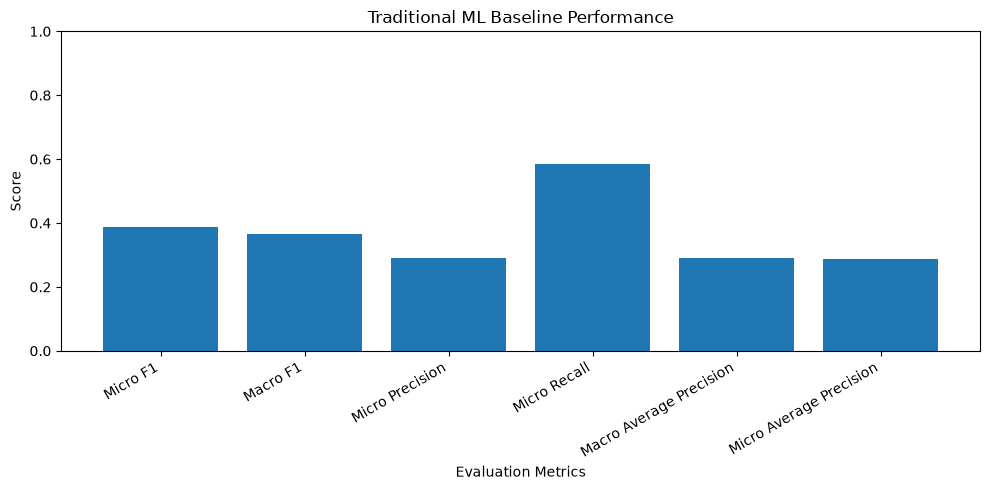

Chart saved to: c:\Users\pyaea\OneDrive\Desktop\protein-function-prediction\protein-function-prediction\results\baseline_metrics_chart.png


In [7]:
import matplotlib.pyplot as plt

# Extract metric names and scores
metric_names = metrics["Metric"]
metric_scores = metrics["Score"]

# Create bar chart
plt.figure(figsize=(10, 5))

plt.bar(metric_names, metric_scores)

plt.title("Traditional ML Baseline Performance")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

# Save chart
chart_path = RESULTS_DIR / "baseline_metrics_chart.png"
plt.savefig(chart_path, dpi=300)

plt.show()

print("Chart saved to:", chart_path)

In [8]:
# Sort GO terms by F1 score
per_term_sorted = per_term.sort_values(
    by="f1",
    ascending=False
)

print("TOP 10 GO TERMS")
display(per_term_sorted.head(10))

print("BOTTOM 10 GO TERMS")
display(per_term_sorted.tail(10))

KeyError: 'f1'

In [9]:
print(per_term.columns.tolist())

['GO_term', 'positive_test_examples', 'F1', 'Average_Precision']


In [10]:
# Sort GO terms by F1 score
per_term_sorted = per_term.sort_values(
    by="F1",
    ascending=False
)

print("TOP 10 GO TERMS")
display(per_term_sorted.head(10))

print("BOTTOM 10 GO TERMS")
display(per_term_sorted.tail(10))

TOP 10 GO TERMS


,GO_term,positive_test_examples,F1,Average_Precision
0,GO:0110165,18121,0.602671,0.692785
1,GO:0005622,14041,0.578419,0.589832
3,GO:0043226,12085,0.541509,0.524261
4,GO:0043229,11563,0.534615,0.511129
5,GO:0005488,11533,0.520682,0.478795
6,GO:0043227,11054,0.511656,0.465093
2,GO:0009987,12203,0.511361,0.461232
7,GO:0005737,10540,0.502737,0.428981
8,GO:0043231,10396,0.499564,0.445820
9,GO:0005515,9646,0.481796,0.418422


BOTTOM 10 GO TERMS


,GO_term,positive_test_examples,F1,Average_Precision
42,GO:0070013,3144,0.273635,0.187335
41,GO:0043233,3144,0.273635,0.187312
45,GO:0080090,3068,0.271856,0.186877
31,GO:0005829,3520,0.270239,0.168606
46,GO:0031323,3040,0.269673,0.186790
32,GO:0043170,3554,0.254755,0.165910
37,GO:0032991,3263,0.253544,0.170579
43,GO:0048519,3082,0.248100,0.158163
44,GO:0048522,3043,0.247953,0.155296
35,GO:0051716,3350,0.229997,0.140671


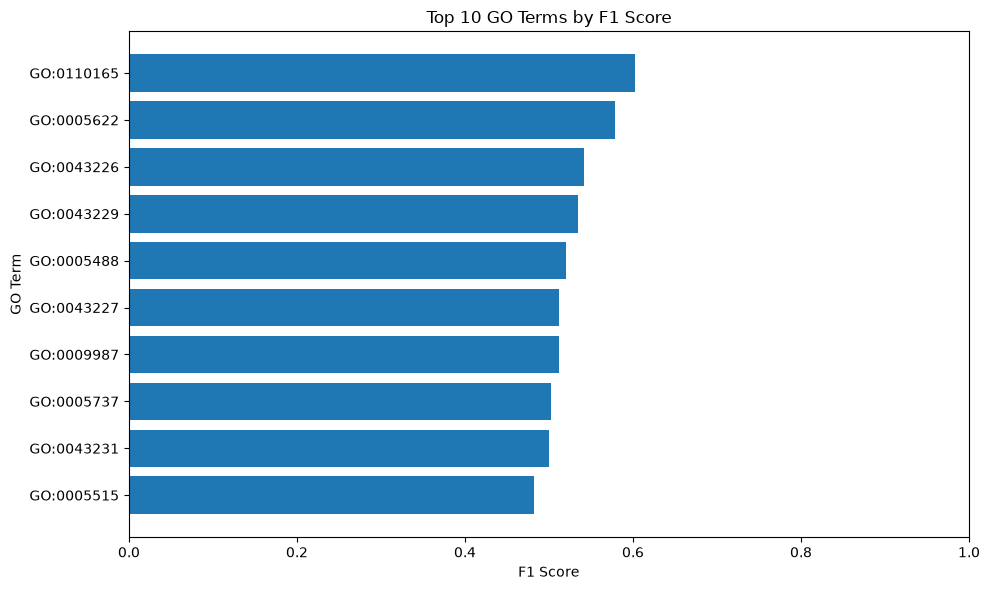

In [11]:
import matplotlib.pyplot as plt

top_10 = per_term_sorted.head(10).sort_values("F1")

plt.figure(figsize=(10, 6))

plt.barh(top_10["GO_term"], top_10["F1"])

plt.title("Top 10 GO Terms by F1 Score")
plt.xlabel("F1 Score")
plt.ylabel("GO Term")
plt.xlim(0, 1)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "top_10_go_terms.png",
    dpi=300
)

plt.show()

## Baseline Model Interpretation

The traditional machine learning model achieved a Micro F1 score of 0.3891
and a Macro F1 score of 0.3655. The model achieved a recall of 0.5856,
meaning it identified more than half of the actual positive protein
function labels.

However, its precision was 0.2913, showing that many predicted
positive labels were incorrect. This suggests that amino acid
composition features provide some useful information but may not
capture all the complex relationships between protein sequences
and their biological functions.

Overall, the baseline provides a starting point for future
experiments using more advanced protein representation methods.

# AI for Protein Function Prediction Using Traditional Machine Learning

## 1. Introduction

Proteins perform important functions in living organisms. Their amino acid sequences contain information about their biological roles. Predicting protein function from these sequences is an important task in computational biology.

This project explores how traditional machine learning can predict protein functions using amino acid composition features. The project uses data from the CAFA 5 dataset and a Logistic Regression classification model.

## 2. Research Objective

The objective is to build and evaluate a traditional machine learning baseline for protein function prediction.

The project focuses on the following question:

**How effectively can amino acid composition features predict selected Gene Ontology (GO) terms using Logistic Regression?**

## 3. Dataset

This project uses the CAFA 5 protein function prediction dataset.

The training data contains:
- 142,246 unique protein sequences.
- 5,363,863 protein function annotation records.
- 31,466 unique Gene Ontology terms.

For this baseline experiment, 47 GO terms were selected after filtering for terms with at least 100 annotated proteins and removing three root terms.

## 4. Methodology

### 4.1 Feature Extraction

Each protein sequence was converted into 20 numerical features representing the relative frequency of the 20 standard amino acids.

This approach is called amino acid composition.

### 4.2 Label Preparation

A binary label matrix was created for the selected 47 GO terms. Each protein was assigned a value of 1 if it had a particular GO annotation and 0 otherwise.

### 4.3 Train-Test Split

The dataset was divided into:
- Training set: 113,796 proteins.
- Testing set: 28,450 proteins.

An 80/20 split was used with a random state of 42.

### 4.4 Model Training

A Logistic Regression model was trained using a One-vs-Rest classification strategy to handle multiple GO-term predictions.

Class weighting was used to help address differences in the number of positive and negative examples.

## 5. Results

The model achieved the following evaluation scores:

| Metric | Score |
|---|---:|
| Micro F1 | 0.3891 |
| Macro F1 | 0.3655 |
| Micro Precision | 0.2913 |
| Micro Recall | 0.5856 |
| Macro Average Precision | 0.2894 |
| Micro Average Precision | 0.2865 |

The results show that the model identified a portion of the actual positive protein function labels, but its precision remained relatively low.

## 6. Discussion

The baseline demonstrates that amino acid composition features contain some useful information for predicting protein functions.

However, amino acid composition only captures the frequency of amino acids. It does not preserve their order or fully represent more complex sequence patterns.

The model's recall was higher than its precision, suggesting that it identified more actual positive labels but also produced many incorrect positive predictions.

These limitations provide opportunities to explore more advanced protein sequence representations.

## 7. Conclusion

This project established a traditional machine learning baseline for protein function prediction using the CAFA 5 dataset.

The experiment included dataset exploration, feature extraction, label preparation, Logistic Regression training, and model evaluation.

The baseline provides a foundation for future experiments comparing traditional machine learning features with pretrained protein language model representations.

## 8. Future Work

Future improvements may include:

- Exploring pretrained protein language models such as ESM-2.
- Comparing amino acid composition with learned protein sequence representations.
- Testing additional machine learning models.
- Evaluating performance across different Gene Ontology categories.
- Improving prediction performance through model and threshold tuning.